# M1: Classifier, streaming and command logic
`Builds on M0 (code.ipynb, m0-progress.md, gestures.md). Chosen set: rest (0), fist (6), abduction of all fingers (5), wrist radial deviation (15), wrist ulnar deviation (16). NinaPro DB5 Exercise 2. The subject comes from `EMG_SUBJECT` in the project's `.env` (change it there, not here).`

In [1]:
# Imports

import importlib
import os
import numpy as np
import matplotlib.pyplot as plt

# The functions from M0 now live in the emg_data folder.
# They get new functions as M1 goes on, so the files are reloaded here: a notebook that has been
# running for a while would otherwise keep using the old copy it loaded earlier.
import emg_data.emg
import emg_data.model
importlib.reload(emg_data.emg)
importlib.reload(emg_data.model)

from emg_data.emg import load_db5, extract_features, held_out_predictions
from emg_data.model import train_model, save_model, load_model, CLASSES, GESTURES


## M1 T1: Refactor into a module
`Done: load_db5, make_windows, extract_features and held_out_predictions are in emg_data/emg.py (same behaviour as the notebook, checked array by array).`

## M1 T2: Train and save the final model
`Train on repetitions 1 to 5, hold out repetition 6`

In [2]:
"Train the final model on repetitions 1 to 5"

# The subject is set in ONE place: EMG_SUBJECT in the project's .env (shared with the browser pipeline).
from dotenv import load_dotenv
load_dotenv(".env", override=True)
subject_number = int(os.environ["EMG_SUBJECT"])
print("subject:", subject_number)
train_reps = [1, 2, 3, 4, 5]     # repetition 6 is held out

emg_windows_s, y_s, rep_s, sampling_freq_s = load_db5(subject_number)
features_s = extract_features(emg_windows_s)

# The short rest at the very end of the recording has rep = 0.
# It belongs to none of the 6 repetitions, so it is left out of training and of the test.
print("windows with rep = 0:", np.sum(rep_s == 0))

model = train_model(features_s, y_s, rep_s, train_reps=train_reps)
print("classes the model knows:", model.classes_)

# How many windows was it trained on, per class?
train_mask = np.isin(y_s, CLASSES) & np.isin(rep_s, train_reps)
for c in model.classes_:
    print(f"   class {c:2d}: {np.sum(y_s[train_mask] == c)} training windows")


subject: 10
windows with rep = 0: 16
classes the model knows: [ 0  5  6 15 16]
   class  0: 4561 training windows
   class  5: 118 training windows
   class  6: 145 training windows
   class 15: 139 training windows
   class 16: 174 training windows


In [3]:
"Test on the held-out repetition 6"

test_mask = np.isin(y_s, CLASSES) & (rep_s == 6)
X_test = features_s[test_mask]
y_test = y_s[test_mask]
y_pred = model.predict(X_test)

recalls = []
print("Repetition 6 only (one repetition, so about 30 windows per gesture):")
for c in model.classes_:
    recall = np.mean(y_pred[y_test == c] == c)       # of the windows that really are class c, how many were predicted c?
    precision = np.mean(y_test[y_pred == c] == c)    # of the windows predicted as c, how many really are c?
    recalls.append(recall)
    print(f"   class {c:2d}: {np.sum(y_test == c):4d} windows, recall {recall * 100:5.1f}%, precision {precision * 100:5.1f}%")

print(f"Average recall over the 5 classes: {np.mean(recalls) * 100:.1f}%")
print(f"Average recall over the 4 gestures (rest left out): {np.mean(recalls[1:]) * 100:.1f}%")


Repetition 6 only (one repetition, so about 30 windows per gesture):
   class  0:  950 windows, recall  99.1%, precision  97.7%
   class  5:   26 windows, recall  65.4%, precision 100.0%
   class  6:   26 windows, recall  80.8%, precision  95.5%
   class 15:   27 windows, recall  74.1%, precision  74.1%
   class 16:   33 windows, recall  84.8%, precision  84.8%
Average recall over the 5 classes: 80.8%
Average recall over the 4 gestures (rest left out): 76.3%


In [4]:
"Check: the numbers should be identical to repetition 6 inside the M0 leave-one-repetition-out run"

# In M0, the model tested on repetition 6 was trained on repetitions 1 to 5, exactly like this model.
# So the predictions for repetition 6 should be identical, not just close.
m0_mask = np.isin(y_s, CLASSES) & (rep_s != 0)
m0_true, m0_pred = held_out_predictions(features_s[m0_mask], y_s[m0_mask], rep_s[m0_mask], equal_priors=True)
m0_rep = rep_s[m0_mask]

print("identical to the M0 repetition-6 fold:", np.array_equal(m0_pred[m0_rep == 6], y_pred))


identical to the M0 repetition-6 fold: True


In [5]:
"Save the model with the information needed to use it later, then load it back"

os.makedirs("models", exist_ok=True)
model_path = f"models/subject{subject_number}_set_a.joblib"

save_model(model, model_path,
           subject=subject_number, exercise=2,
           train_reps=train_reps, held_out_rep=6,
           window_length=50, step_size=25, sampling_freq=sampling_freq_s,
           features="MAV, RMS, WL for each of the 16 channels (48 numbers)",
           equal_priors=True, gestures=GESTURES)

loaded = load_model(model_path)
print("saved keys:", list(loaded.keys()))
print("classes:", loaded["classes"])
print("same predictions after loading:", np.array_equal(loaded["model"].predict(X_test), y_pred))
print(f"file size: {os.path.getsize(model_path) / 1024:.0f} KB")


saved keys: ['model', 'classes', 'sklearn_version', 'subject', 'exercise', 'train_reps', 'held_out_rep', 'window_length', 'step_size', 'sampling_freq', 'features', 'equal_priors', 'gestures']
classes: [0, 5, 6, 15, 16]
same predictions after loading: True
file size: 22 KB


## M1 T3: Streaming classifier
`Replay real recorded pieces (repetition 6 only) as if they came from a sensor, one window every 125 ms`

In [6]:
"Build the replay: real rest + gesture pieces from repetition 6, in the demo order"

from emg_data.stream import build_replay, stream_windows

# No hand-picked order: the pieces play in the order they appear in the recording.

replay = build_replay(subject_number=subject_number, replay_rep=6)
replay_order = [segment["gesture"] for segment in replay["segments"]]   # recording order
replay_emg = replay["emg"]
replay_labels = replay["labels"]
fs = replay["sampling_freq"]

print("replay:", replay_emg.shape, "=", round(len(replay_emg) / fs, 1), "seconds")
for segment in replay["segments"]:
    print(f"   gesture {segment['gesture']:2d} ({GESTURES[segment['gesture']]}): "
          f"rest from {segment['rest_start'] / fs:5.2f} s, "
          f"gesture from {segment['gesture_start'] / fs:5.2f} s to {segment['gesture_end'] / fs:5.2f} s")


replay: (8532, 16) = 42.7 seconds
   gesture  5 (abduction of all fingers): rest from  0.00 s, gesture from  9.24 s to 12.48 s
   gesture  6 (fist): rest from 12.48 s, gesture from 19.43 s to 22.68 s
   gesture 15 (wrist radial deviation): rest from 22.68 s, gesture from 29.17 s to 32.45 s
   gesture 16 (wrist ulnar deviation): rest from 32.45 s, gesture from 38.57 s to 42.66 s


In [7]:
"Stream the first 10 windows at real speed (speed=1.0): one window every 125 ms"

import time

start_wall_clock = time.perf_counter()
count = 0
for item in stream_windows(replay_emg, model, labels=replay_labels, sampling_freq=fs, speed=1.0):
    print(f"t = {item['t']:.3f} s   predicted {item['label']:2d}   confidence {item['confidence']:.3f}   true {item['true_label']}")
    count += 1
    if count == 10:
        break

print(f"wall-clock time for 10 windows: {time.perf_counter() - start_wall_clock:.2f} s (expected about 1.4 s)")


t = 0.250 s   predicted  0   confidence 0.940   true 0
t = 0.375 s   predicted  0   confidence 0.922   true 0


t = 0.500 s   predicted  0   confidence 0.919   true 0
t = 0.625 s   predicted  0   confidence 0.986   true 0


t = 0.750 s   predicted  0   confidence 0.989   true 0
t = 0.875 s   predicted  0   confidence 0.985   true 0


t = 1.000 s   predicted  0   confidence 0.991   true 0
t = 1.125 s   predicted  0   confidence 0.995   true 0


t = 1.250 s   predicted  0   confidence 0.995   true 0
t = 1.375 s   predicted  0   confidence 0.993   true 0
wall-clock time for 10 windows: 1.38 s (expected about 1.4 s)


In [8]:
"Stream the whole replay as fast as possible (speed=None) and check it"

from emg_data.emg import make_windows

items = list(stream_windows(replay_emg, model, labels=replay_labels, sampling_freq=fs))
predicted = np.array([item["label"] for item in items])
true = np.array([item["true_label"] for item in items])
confidence = np.array([item["confidence"] for item in items])
times = np.array([item["t"] for item in items])
print("windows:", len(items))

# Check: the stream gives the same predictions as predicting all windows in one go
direct = model.predict(extract_features(make_windows(replay_emg, 50, 25)))
print("same predictions as model.predict on all windows:", np.array_equal(predicted, direct))

# Window-level recall on this replay (not the same windows as in T2, because the pieces are joined here)
for c in model.classes_:
    mask = true == c
    print(f"   class {c:2d}: {mask.sum():3d} windows, recall {np.mean(predicted[mask] == c) * 100:5.1f}%")

# How sure is the model when it is right, and when it is wrong?
right = predicted == true
print(f"median confidence when right: {np.median(confidence[right]):.3f}")
print(f"median confidence when wrong: {np.median(confidence[~right]):.3f}  ({np.sum(~right)} wrong windows)")
print(f"wrong windows with confidence above 0.9: {np.sum(confidence[~right] > 0.9)}")


windows: 340
same predictions as model.predict on all windows: True
   class  0: 230 windows, recall  99.6%
   class  5:  26 windows, recall  65.4%
   class  6:  26 windows, recall  80.8%
   class 15:  26 windows, recall  76.9%
   class 16:  32 windows, recall  84.4%
median confidence when right: 0.993
median confidence when wrong: 0.654  (26 wrong windows)
wrong windows with confidence above 0.9: 3


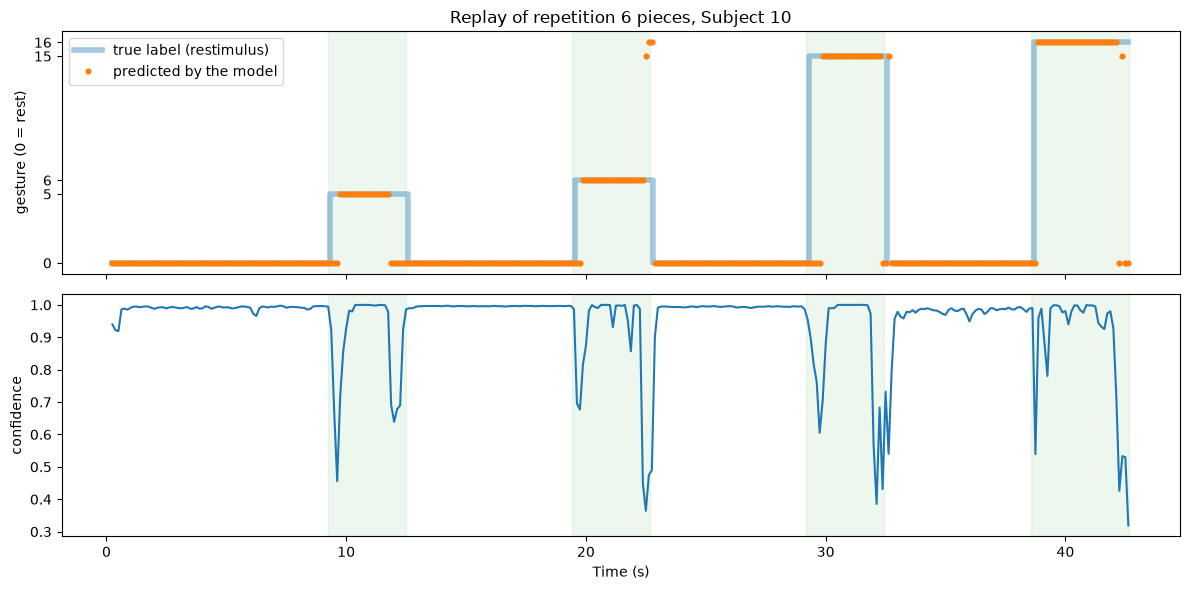

In [9]:
"Plot: true label, predicted label and confidence over time"

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 6))

axes[0].step(times, true, where='mid', linewidth=4, alpha=0.4, label='true label (restimulus)')
axes[0].plot(times, predicted, '.', markersize=7, label='predicted by the model')
axes[0].set_yticks(list(model.classes_))
axes[0].set_ylabel('gesture (0 = rest)')
axes[0].set_title(f'Replay of repetition 6 pieces, Subject {subject_number}')
axes[0].legend(loc='upper left')

axes[1].plot(times, confidence)
axes[1].set_ylabel('confidence')
axes[1].set_xlabel('Time (s)')

# Shade the four real gesture pieces
for segment in replay["segments"]:
    for ax in axes:
        ax.axvspan(segment['gesture_start'] / fs, segment['gesture_end'] / fs, alpha=0.08, color='tab:green')

fig.tight_layout()
save_path = r"m1_stream_predictions.png"
fig.savefig(save_path, dpi=150)
plt.show()


## M1 T4: Smoothing and command logic
`Majority vote over the last windows, minimum confidence, cooldown, hold-to-repeat for scroll, fire-once for back and forward. Default settings from the plan; they are tuned in T5.`

In [10]:
"Run the command logic over the replay and list the commands it gives"

from emg_data.commands import CommandLogic, DEFAULT_CONFIG, COMMAND_FOR_GESTURE

print("settings:", DEFAULT_CONFIG)

# items = the windows streamed in T3 (one dict per window)
logic = CommandLogic(DEFAULT_CONFIG)
events = []        # the commands that were fired
smoothed = []      # the smoothed state after every window (0 = rest, -1 = undecided)

for item in items:
    event = logic.update(item)
    if logic.state is None:
        smoothed.append(-1)
    else:
        smoothed.append(logic.state)
    if event is not None:
        events.append(event)

smoothed = np.array(smoothed)

print("commands fired:", len(events))
for event in events:
    print(f"   t = {event['t']:6.3f} s   {event['command']:12s} (gesture {event['gesture']:2d})   confidence {event['confidence']:.3f}")


settings: {'vote_window': 5, 'min_confidence': 0.6, 'cooldown_s': 1.0, 'repeat_every_s': 0.3}
commands fired: 15
   t = 10.000 s   scroll_up    (gesture  5)   confidence 0.834
   t = 10.375 s   scroll_up    (gesture  5)   confidence 0.949
   t = 10.750 s   scroll_up    (gesture  5)   confidence 0.996
   t = 11.125 s   scroll_up    (gesture  5)   confidence 1.000
   t = 11.500 s   scroll_up    (gesture  5)   confidence 0.999
   t = 11.875 s   scroll_up    (gesture  5)   confidence 0.994
   t = 20.125 s   scroll_down  (gesture  6)   confidence 0.890
   t = 20.500 s   scroll_down  (gesture  6)   confidence 0.968
   t = 20.875 s   scroll_down  (gesture  6)   confidence 0.997
   t = 21.250 s   scroll_down  (gesture  6)   confidence 0.986
   t = 21.625 s   scroll_down  (gesture  6)   confidence 0.985
   t = 22.000 s   scroll_down  (gesture  6)   confidence 0.960
   t = 22.375 s   scroll_down  (gesture  6)   confidence 0.961
   t = 30.125 s   back         (gesture 15)   confidence 0.857
   t 

In [11]:
"For each real gesture piece: which commands came out, and how long after the gesture started?"

# Only 4 gesture pieces, so this is a first look, not the evaluation (that is T5).
# The latency is measured from the start of the gesture in restimulus.

for segment in replay["segments"]:
    gesture = segment["gesture"]
    onset = segment["gesture_start"] / fs
    offset = segment["gesture_end"] / fs

    # the commands that fired while the gesture was happening (and a quarter of a second after it ended)
    inside = []
    for event in events:
        if onset <= event["t"] <= offset + 0.25:
            inside.append(event)

    names = sorted(set(event["command"] for event in inside))
    expected = COMMAND_FOR_GESTURE[gesture]

    if len(inside) == 0:
        print(f"gesture {gesture:2d}: NO command fired (expected {expected})")
    else:
        latency = inside[0]["t"] - onset
        print(f"gesture {gesture:2d}: {len(inside)} command(s) {names}, expected {expected}, "
              f"first one {latency:.2f} s after the gesture started")

# Commands that fired while no gesture piece was happening would be false triggers
outside = []
for event in events:
    during_a_gesture = False
    for segment in replay["segments"]:
        if segment["gesture_start"] / fs <= event["t"] <= segment["gesture_end"] / fs + 0.25:
            during_a_gesture = True
    if not during_a_gesture:
        outside.append(event)

print("commands outside every gesture piece:", len(outside))


gesture  5: 6 command(s) ['scroll_up'], expected scroll_up, first one 0.76 s after the gesture started
gesture  6: 7 command(s) ['scroll_down'], expected scroll_down, first one 0.70 s after the gesture started
gesture 15: 1 command(s) ['back'], expected back, first one 0.95 s after the gesture started
gesture 16: 1 command(s) ['forward'], expected forward, first one 0.55 s after the gesture started
commands outside every gesture piece: 0


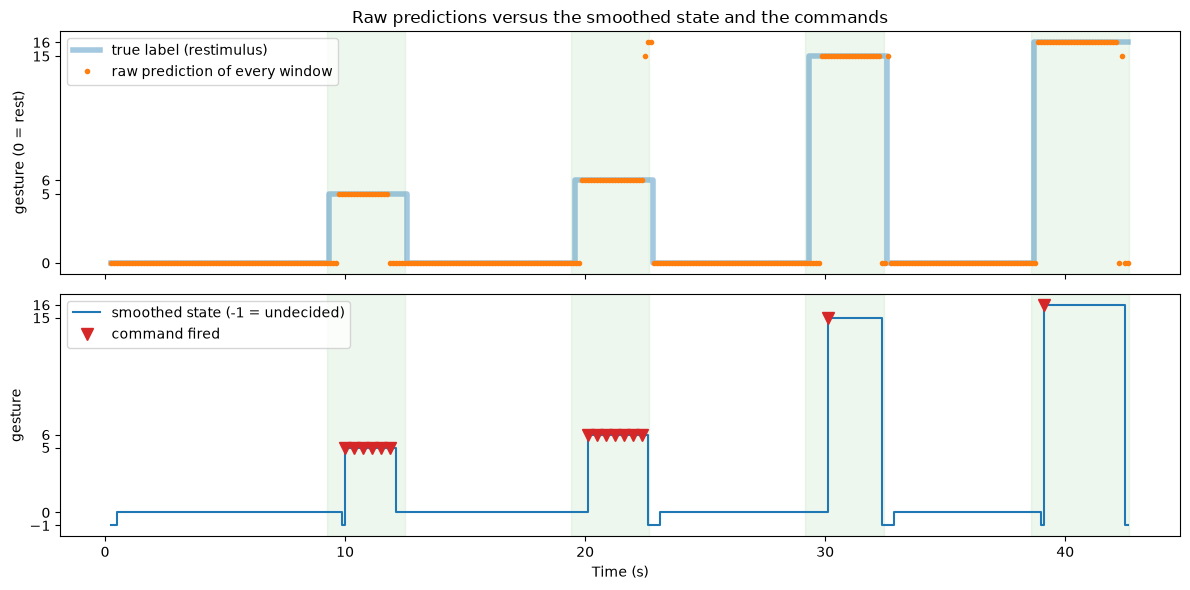

In [12]:
"Plot: raw predictions, smoothed state and the commands that fired"

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 6))

# Top: what the model said, window by window
axes[0].step(times, true, where='mid', linewidth=4, alpha=0.4, label='true label (restimulus)')
axes[0].plot(times, predicted, '.', markersize=6, label='raw prediction of every window')
axes[0].set_yticks(list(model.classes_))
axes[0].set_ylabel('gesture (0 = rest)')
axes[0].set_title('Raw predictions versus the smoothed state and the commands')
axes[0].legend(loc='upper left')

# Bottom: after the majority vote and the confidence threshold
axes[1].step(times, smoothed, where='post', label='smoothed state (-1 = undecided)')
axes[1].plot([e['t'] for e in events], [e['gesture'] for e in events], 'v', color='tab:red',
             markersize=9, label='command fired')
axes[1].set_yticks([-1] + list(model.classes_))
axes[1].set_ylabel('gesture')
axes[1].set_xlabel('Time (s)')
axes[1].legend(loc='upper left')

# Shade the four real gesture pieces
for segment in replay["segments"]:
    for ax in axes:
        ax.axvspan(segment['gesture_start'] / fs, segment['gesture_end'] / fs, alpha=0.08, color='tab:green')

fig.tight_layout()
save_path = r"m1_commands.png"
fig.savefig(save_path, dpi=150)
plt.show()


## M1 T5: Evaluate at event level and tune
`Not window accuracy but commands: right command given, wrong command given, command when nothing was happening, and how long it takes. Tune on repetitions 1 to 5 (train on four, replay the fifth), then look at repetition 6 once.`

In [13]:
"Build the folds: for each repetition 1 to 5, train on the other four and replay the held-out one"

import importlib
import emg_data.stream
import emg_data.evaluation
importlib.reload(emg_data.stream)         # use the newest files (stream.py gained build_rest_replay)
importlib.reload(emg_data.evaluation)
from emg_data.evaluation import build_fold, evaluate_folds

tuning_reps = [1, 2, 3, 4, 5]             # repetition 6 is NOT used in this part

# For every fold we replay two things from the held-out repetition:
#   1. the 4 gesture pieces (real rest + gesture, as in T3)
#   2. ALL the rest of that repetition, from the rest periods before all 17 movements.
#      No gesture happens in it, so every command in it is a false trigger.
folds = []
for r in tuning_reps:
    other_reps = [k for k in tuning_reps if k != r]
    fold_model = train_model(features_s, y_s, rep_s, train_reps=other_reps)    # never sees repetition r or 6
    fold = build_fold(fold_model, replay_rep=r, subject_number=subject_number)
    folds.append(fold)
    print(f"held-out repetition {r}: trained on {other_reps}, "
          f"gesture replay {fold['gesture_seconds']:.1f} s, rest-only replay {fold['rest_only_seconds']:.1f} s")

total_rest = sum(fold["rest_only_seconds"] for fold in folds)
print(f"rest-only replays together: {total_rest / 60:.1f} minutes")


held-out repetition 1: trained on [2, 3, 4, 5], gesture replay 42.9 s, rest-only replay 113.4 s
held-out repetition 2: trained on [1, 3, 4, 5], gesture replay 39.4 s, rest-only replay 105.0 s


held-out repetition 3: trained on [1, 2, 4, 5], gesture replay 41.1 s, rest-only replay 120.9 s
held-out repetition 4: trained on [1, 2, 3, 5], gesture replay 41.0 s, rest-only replay 119.2 s


held-out repetition 5: trained on [1, 2, 3, 4], gesture replay 41.1 s, rest-only replay 111.8 s
rest-only replays together: 9.5 minutes


In [14]:
"Event-level metrics with the default settings (repetitions 1 to 5, pooled)"

def print_metrics(name, m):
    print(name)
    print(f"   gesture pieces that got the right command: {m['detected']} of {m['n_pieces']}")
    print(f"   pieces where a wrong command also fired:   {m['wrong']} of {m['n_pieces']}")
    print(f"   false triggers: {m['false_triggers']} in {m['rest_minutes']:.1f} minutes of rest "
          f"= {m['false_per_minute']:.2f} per minute")
    if m["latency_median"] is not None:
        print(f"   time from gesture start to the first right command: "
              f"median {m['latency_median']:.2f} s, longest {m['latency_max']:.2f} s")

default_metrics = evaluate_folds(folds, DEFAULT_CONFIG)
print_metrics(f"Default settings {DEFAULT_CONFIG}", default_metrics)

# The same, gesture by gesture
print("by gesture:")
for gesture in replay_order:
    mine = [p for p in default_metrics["pieces"] if p["gesture"] == gesture]
    latencies = [p["latency"] for p in mine if p["latency"] is not None]
    print(f"   gesture {gesture:2d} ({COMMAND_FOR_GESTURE[gesture]:11s}): "
          f"{sum(p['detected'] for p in mine)} of {len(mine)} detected, "
          f"{sum(p['wrong'] for p in mine)} with a wrong command, "
          f"median latency {np.median(latencies):.2f} s")


Default settings {'vote_window': 5, 'min_confidence': 0.6, 'cooldown_s': 1.0, 'repeat_every_s': 0.3}
   gesture pieces that got the right command: 20 of 20
   pieces where a wrong command also fired:   5 of 20
   false triggers: 0 in 11.6 minutes of rest = 0.00 per minute
   time from gesture start to the first right command: median 0.78 s, longest 1.48 s
by gesture:
   gesture  5 (scroll_up  ): 5 of 5 detected, 1 with a wrong command, median latency 0.75 s
   gesture  6 (scroll_down): 5 of 5 detected, 2 with a wrong command, median latency 0.82 s
   gesture 15 (back       ): 5 of 5 detected, 1 with a wrong command, median latency 0.91 s
   gesture 16 (forward    ): 5 of 5 detected, 1 with a wrong command, median latency 0.79 s


In [15]:
"Try other settings on the same folds: length of the vote x minimum confidence"

results = []     # (settings, metrics) for every combination
for vote_window in [3, 5, 7, 9, 11]:
    for min_confidence in [0.5, 0.6, 0.8, 0.9, 0.95, 0.99]:
        settings = dict(DEFAULT_CONFIG)
        settings["vote_window"] = vote_window
        settings["min_confidence"] = min_confidence
        results.append((settings, evaluate_folds(folds, settings)))

# How the best one is chosen (fixed here, before repetition 6 is looked at):
#   1. at most 1 false trigger per minute
#   2. then the fewest wrong commands, then the most gestures detected,
#      then the fewest false triggers, then the lowest median latency
allowed = []
for settings, m in results:
    if m["false_per_minute"] <= 1.0:
        allowed.append((settings, m))
allowed.sort(key=lambda r: (r[1]["wrong"], -r[1]["detected"], r[1]["false_triggers"], r[1]["latency_median"]))

print("vote  min_conf  detected  wrong  false/min  latency median / longest")
for settings, m in allowed[:10]:
    print(f"{settings['vote_window']:4d}  {settings['min_confidence']:8.2f}  {m['detected']:5d}/{m['n_pieces']}  "
          f"{m['wrong']:5d}  {m['false_per_minute']:9.2f}  {m['latency_median']:.2f} s / {m['latency_max']:.2f} s")

chosen_config = allowed[0][0]
best = allowed[0][1]
print("chosen settings:", chosen_config)

# How many settings are just as good as the chosen one on the first three criteria?
tied = 0
for settings, m in allowed:
    if (m["wrong"], m["detected"], m["false_triggers"]) == (best["wrong"], best["detected"], best["false_triggers"]):
        tied += 1
print(f"settings tied with it on wrong / detected / false triggers: {tied} of {len(results)}")


vote  min_conf  detected  wrong  false/min  latency median / longest
   3      0.95     20/20      0       0.00  0.89 s / 2.27 s
   5      0.90     20/20      0       0.00  0.93 s / 1.48 s
   7      0.80     20/20      0       0.00  0.99 s / 1.61 s
   9      0.80     20/20      0       0.00  1.11 s / 2.02 s
   9      0.90     20/20      0       0.00  1.18 s / 2.27 s
  11      0.80     20/20      0       0.09  1.24 s / 2.15 s
  11      0.90     20/20      0       0.17  1.30 s / 2.27 s
   3      0.99     19/20      0       0.00  0.98 s / 1.66 s
   5      0.99     19/20      0       0.00  1.10 s / 1.79 s
   7      0.99     19/20      0       0.00  1.28 s / 1.91 s
chosen settings: {'vote_window': 3, 'min_confidence': 0.95, 'cooldown_s': 1.0, 'repeat_every_s': 0.3}
settings tied with it on wrong / detected / false triggers: 5 of 30


In [16]:
"Does the cooldown matter? Same chosen settings with three different cooldowns"

for cooldown_s in [0.5, 1.0, 1.5]:
    settings = dict(chosen_config)
    settings["cooldown_s"] = cooldown_s
    m = evaluate_folds(folds, settings)
    print(f"cooldown {cooldown_s} s: detected {m['detected']}/{m['n_pieces']}, wrong {m['wrong']}, "
          f"false triggers {m['false_triggers']}, median latency {m['latency_median']:.2f} s")


cooldown 0.5 s: detected 20/20, wrong 0, false triggers 0, median latency 0.89 s
cooldown 1.0 s: detected 20/20, wrong 0, false triggers 0, median latency 0.89 s
cooldown 1.5 s: detected 20/20, wrong 0, false triggers 0, median latency 0.89 s


In [17]:
"Final check on repetition 6 (held out from training and from the tuning). Look at it once."

# The final model from T2 was trained on repetitions 1 to 5 and has never seen repetition 6.
fold_6 = build_fold(model, replay_rep=6, subject_number=subject_number)

final_default = evaluate_folds([fold_6], DEFAULT_CONFIG)
final_chosen = evaluate_folds([fold_6], chosen_config)

print_metrics("Repetition 6, default settings", final_default)
print_metrics("Repetition 6, chosen settings", final_chosen)

print("piece by piece with the chosen settings:")
for p in final_chosen["pieces"]:
    if p["latency"] is None:
        print(f"   gesture {p['gesture']:2d} ({COMMAND_FOR_GESTURE[p['gesture']]}): NOT detected, wrong command: {p['wrong']}")
    else:
        print(f"   gesture {p['gesture']:2d} ({COMMAND_FOR_GESTURE[p['gesture']]}): detected after {p['latency']:.2f} s, wrong command: {p['wrong']}")


Repetition 6, default settings
   gesture pieces that got the right command: 4 of 4
   pieces where a wrong command also fired:   0 of 4
   false triggers: 1 in 2.4 minutes of rest = 0.41 per minute
   time from gesture start to the first right command: median 0.73 s, longest 0.95 s
Repetition 6, chosen settings
   gesture pieces that got the right command: 4 of 4
   pieces where a wrong command also fired:   0 of 4
   false triggers: 0 in 2.4 minutes of rest = 0.00 per minute
   time from gesture start to the first right command: median 0.92 s, longest 1.08 s
piece by piece with the chosen settings:
   gesture  5 (scroll_up): detected after 1.01 s, wrong command: False
   gesture  6 (scroll_down): detected after 0.82 s, wrong command: False
   gesture 15 (back): detected after 1.08 s, wrong command: False
   gesture 16 (forward): detected after 0.43 s, wrong command: False


## M1 T6: Interface for the agent and the dashboard
`One function replays recorded EMG and yields every window with the command that fired on it. The formats are written down in INTERFACE.md.`

In [18]:
"Use the interface like the agent would: replay and print the commands"

import json
import emg_data.commands
import emg_data.interface
importlib.reload(emg_data.commands)       # use the newest files (commands.py gained TUNED_CONFIG)
importlib.reload(emg_data.interface)
from emg_data.interface import replay_commands, to_json_dict
from emg_data.commands import TUNED_CONFIG

print("settings used by default:", TUNED_CONFIG)
print("same as the settings chosen in T5:", TUNED_CONFIG == chosen_config)

# speed=None runs as fast as possible. Use speed=1.0 for real time (one window every 125 ms).
commands_fired = []
for window in replay_commands(model_path=model_path, subject_number=subject_number, speed=None):
    if window["event"] is not None:
        commands_fired.append(window["event"])

print("commands fired:", len(commands_fired))
for event in commands_fired:
    print(f"   t = {event['t']:6.3f} s   {event['command']}")

# One window as JSON, the way the dashboard would receive it (without the raw 50 x 16 window)
for window in replay_commands(model_path=model_path, subject_number=subject_number, speed=None):
    if window["event"] is not None:
        print(json.dumps(to_json_dict(window), indent=1))
        break


settings used by default: {'vote_window': 5, 'min_confidence': 0.9, 'cooldown_s': 1.0, 'repeat_every_s': 0.3}
same as the settings chosen in T5: False


commands fired: 13
   t = 10.250 s   scroll_up
   t = 10.625 s   scroll_up
   t = 11.000 s   scroll_up
   t = 11.375 s   scroll_up
   t = 11.750 s   scroll_up
   t = 20.375 s   scroll_down
   t = 20.750 s   scroll_down
   t = 21.125 s   scroll_down
   t = 21.500 s   scroll_down
   t = 21.875 s   scroll_down
   t = 22.250 s   scroll_down
   t = 30.375 s   back
   t = 39.375 s   forward


{
 "t": 10.25,
 "index": 80,
 "label": 5,
 "confidence": 0.9792873806279463,
 "probabilities": {
  "0": 1.1780907110608757e-06,
  "5": 0.9792873806279463,
  "6": 1.3474582180204168e-05,
  "15": 9.0724171633372e-06,
  "16": 0.020688894281998917
 },
 "true_label": 5,
 "event": {
  "t": 10.25,
  "command": "scroll_up",
  "gesture": 5,
  "confidence": 0.9631694564549079
 }
}
